# A learned inverse map and its test set

**Question:** On the same held-out synthetic realizations, how does CNN column-density error compare with the classical inverse?
**Level 1 — Foundations**  
**Prerequisites:** Python basics; 35 min.

## Objectives

Reconstruct physical-unit CNN errors from saved normalization and compare them case by case with the classical inverse on identical held-out realizations.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Data

Training ledger stores splits, normalized test errors, model metrics and a separately evaluated OOD control.

## Method

M12 predicts a depth-integrated density column from gravity-derived inputs; its target is not a 3D model. The ledger uses 800/160/160 train/validation/test realizations, disjoint generator seeds and withholds oblique/ring geometries from training. Classical and CNN estimates share 160 test cases. The executed held-out comparison recomputes their physical-unit MSEs from the ledger; the values are printed by the verification cell below, rather than copied as stale prose. Reconstruct paired per-case CNN errors using the declared target scale squared, plot classical-vs-CNN errors and the paired difference, and report fraction improved and median gain. This tests one synthetic generator and split design, not field geology, acquisition shifts or uncertainty calibration; averages can conceal regressions.

The split is by generator realization, and the CNN target is a depth-integrated density column. Undo target normalization by multiplying squared normalized errors by target_scale² before comparing MSE. Paired cases control difficulty, but all 160 draws come from one synthetic generator; they do not represent independent geology or acquisition domains.

## Results

**Answer:** Fresh CNN inference reproduces 160 held-out errors. Physical MSE is 755.757 (g/cm³·m)² versus 1441.328 for the paired classical inverse on the same synthetic test cases.

## Summary

The frozen CNN reduces mean error for a depth-integrated column target in this generator. It does not recover 3D structure; a separate site and acquisition design are needed to assess transfer.

## References

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)


### Diagnostic: split and checkpoint provenance

Inspect the exact train, validation and test partitions before comparing the model outputs.

In [1]:
from pathlib import Path
from importlib.metadata import version
import json

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
# Load paired test errors and undo the ledger's declared CNN target normalization.
d = json.loads((root / "data/derived/v2/models/training.json").read_text(encoding="utf-8"))
a = np.asarray(d["classical_test_errors"], float)
b = np.asarray(d["models"]["cnn"]["test_errors"], float) * d["target_scale"] ** 2


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}


### Load the frozen CNN and autoencoder together with the gravity operator used to build the benchmark. The bundle loader verifies checkpoint metadata and exposes normalization scales; these are necessary to turn model outputs back into physical density units. Loading weights is not training, and the test set remains untouched during model selection.

Cargue la CNN y el autoencoder congelados junto con el operador gravimétrico del benchmark. El cargador verifica metadatos del checkpoint y entrega escalas de normalización necesarias para expresar la salida en unidades físicas de densidad. Cargar pesos no es entrenar, y el conjunto de prueba permanece fuera de la selección.

In [2]:
print(
    "splits",
    d["split_counts"],
    d["split_policy"],
    "cases",
    len(a),
    "unit",
    d["units"],
    "stored MSE",
    d["classical_test_mse"],
    d["cnn_test_mse"],
    "recomputed",
    a.mean(),
    b.mean(),
)
# Load the actual checkpoint and forward operator used by the held-out protocol.
import sys, torch, hashlib

sys.path.insert(0, str(root / "data-pipeline"))
import geology, learning, potential

cnn_model, ae_model, training_meta = learning.load_bundle(root / "data/derived/v2/models")
mesh_real, _, G_real, _ = potential.operators()


splits [800, 160, 160] Disjoint generator seeds; complete realization assigned to one split; oblique and ring geometries withheld from training cases 160 unit (g/cm³ m)² stored MSE 1441.3277421693122 755.7566463947296 recomputed 1441.3277421693124 755.7565736933611


### Diagnostic: paired error scale

Restore physical units before interpreting the paired CNN and classical errors.

CNN better fraction 0.79375 median gain 469.33024381926634 (g/cm³ m)²


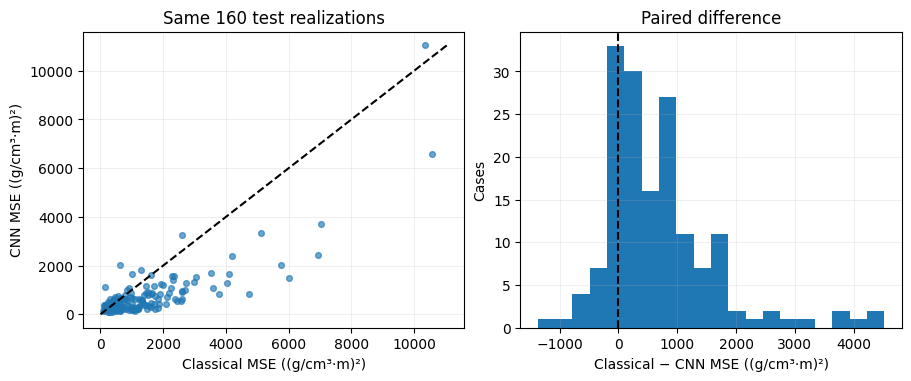

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Compare paired errors; points below the diagonal are cases where CNN MSE is lower.
import matplotlib.pyplot as plt

delta = a - b
lim = max(a.max(), b.max())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.7), constrained_layout=True)
ax[0].scatter(a, b, s=17, alpha=0.65)
ax[0].plot([0, lim], [0, lim], "k--")
ax[0].set(
    xlabel="Classical MSE ((g/cm³·m)²)", ylabel="CNN MSE ((g/cm³·m)²)", title="Same 160 test realizations"
)
ax[1].hist(delta, bins=20)
ax[1].axvline(0, color="black", ls="--")
ax[1].set(xlabel="Classical − CNN MSE ((g/cm³·m)²)", ylabel="Cases", title="Paired difference")
[x.grid(alpha=0.2) for x in ax]
print("CNN better fraction", (delta > 0).mean(), "median gain", np.median(delta), d["units"])
plt.show()


### Experiment: paired uncertainty within the declared test generator

The train/dev/test split is by complete synthetic realization and disjoint generator seeds; oblique and ring families are deliberately withheld from training. Recompute a paired bootstrap interval for the mean per-realization MSE difference `classical − CNN` on the **same 160 test cases**. This quantifies sampling uncertainty within this generator only. It does not estimate uncertainty across real sites, alternative geology, survey layouts, or noise laws. Confirm the stored counts and normalization before interpreting the interval; do not use this test interval to select epochs or hyperparameters.

In [4]:
# Paired bootstrap: resample test realizations, preserving the matched-input comparison.
assert d["split_counts"] == [800, 160, 160] and len(a) == len(b) == 160
assert np.isclose(b.mean(), d["cnn_test_mse"], rtol=1e-6)
rng = np.random.default_rng(20261027)
boot = np.empty(5000)
for j in range(len(boot)):
    idx = rng.integers(0, len(a), len(a))
    boot[j] = np.mean(a[idx] - b[idx])
lo, hi = np.quantile(boot, [0.025, 0.975])
print(
    (f"Paired test mean(classical-CNN)={np.mean(a-b):.3f} (g/cm^3 m)^2; "
     f"within-generator 95% bootstrap interval [{lo:.3f}, {hi:.3f}]")
)
print("Bootstrap resamples realizations, not voxels; interval does not cover field-domain shift.")


Paired test mean(classical-CNN)=685.571 (g/cm^3 m)^2; within-generator 95% bootstrap interval [540.350, 840.856]
Bootstrap resamples realizations, not voxels; interval does not cover field-domain shift.


### Rebuild the complete held-out test inputs

The full held-out test cohort is rebuilt with the pinned generator, forward operator, and split seed. These are the benchmark’s synthetic held-out inputs, not illustrative toy arrays or field observations.


In [5]:
# Regenerate the exact 160 test volumes and gravity observations from the ledger seed.
test_models = learning.generate(mesh_real.cell_centers, 160, training_meta["seeds"][2])
test_clean = test_models @ G_real.T
print("test models and clean observations", test_models.shape, test_clean.shape)


test models and clean observations (160, 10752) (160, 1024)


### Verify the recorded test noise bytes

Advance the seeded stream over train and validation before the test partition; the SHA-256 binds this input to the persisted benchmark receipt.


In [6]:
# Advance the documented noise stream through train and validation before test.
noise_rng = np.random.default_rng(5001)
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (800, G_real.shape[0]))
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (160, G_real.shape[0]))
test_noise = noise_rng.normal(0, 0.02 * training_meta["input_scale"], test_clean.shape)
test_input = test_clean + test_noise
test_sha = hashlib.sha256(test_input.astype("<f8").tobytes()).hexdigest()
assert test_sha == training_meta["comparison"]["noisy_test_sha256"]
print("held-out input SHA-256 verified", test_sha)


held-out input SHA-256 verified 75fee10c9c19cff26ae51a02258ddd24c1958bf812c8b445abb3881e35b29940


### Run the frozen CNN on test cases

The frozen network predicts depth-integrated density on these exact noisy observations. The truth projection uses the mesh’s physical vertical spacing; no weights are retrained.


In [7]:
# Infer the depth-integrated density target on the exact noisy held-out observations.
from geology import VOLUME_SHAPE, VOLUME_SPACING

x_test = torch.as_tensor(
    test_input / training_meta["input_scale"], dtype=torch.float32, device=next(cnn_model.parameters()).device
).reshape(-1, 1, *training_meta["survey_shape"])
y_test = test_models.reshape(-1, *VOLUME_SHAPE).sum(1) * VOLUME_SPACING[2] / training_meta["target_scale"]
with torch.no_grad():
    pred_test = cnn_model(x_test).cpu().numpy()
cnn_errors = np.mean((pred_test - y_test) ** 2, axis=(1, 2))
print("inferred cases", len(cnn_errors), "mean normalized MSE", float(cnn_errors.mean()))


inferred cases 160 mean normalized MSE 0.004723478481682726


### Verify paired CNN and classical errors

Per-case CNN errors are converted to physical units and compared to the committed ledger. The classical comparator is paired on the same inputs; this remains synthetic-generator evidence.


In [8]:
# Reconstruct physical-unit paired CNN errors and verify each recorded test case.
cnn_mse_physical = cnn_errors * training_meta["target_scale"] ** 2
recorded_cnn = np.asarray(training_meta["models"]["cnn"]["test_errors"]) * training_meta["target_scale"] ** 2
assert np.allclose(cnn_mse_physical, recorded_cnn, rtol=2e-4, atol=2e-4)
classical_mse = np.asarray(training_meta["classical_test_errors"])
print("CNN physical MSE", float(cnn_mse_physical.mean()), "classical", float(classical_mse.mean()))


CNN physical MSE 755.7565570692364 classical 1441.3277421693124


### Score physical column recovery with the repository evaluator

The CNN output and integrated synthetic target are restored to density-times-depth units before the shared recovery diagnostic is applied. The zero model is the evaluator's declared baseline. This statistic describes the held-out synthetic volume projections, not 3D depth localization.


In [9]:
# Score the actual held-out column estimates with the repository evaluator.
from evaluation import model_metrics

physical_prediction = pred_test * training_meta["target_scale"]
physical_truth = y_test * training_meta["target_scale"]
heldout_recovery = model_metrics(physical_prediction, physical_truth)
print("held-out column RMSE", heldout_recovery["model_rmse"])
print("zero-start ratio", heldout_recovery["baseline_ratio"])


held-out column RMSE 27.491026845187832
zero-start ratio 0.36162633287599516
